# Tax-loss harvesting: what it does, what it costs, what it cannot do

When a stock you own has fallen, selling it makes a **capital loss**. In a taxable account that loss cancels capital gains (this year, the three years before, or any later year), so it lowers your tax. **Harvesting** means selling a loser on purpose, near the end of the year, for that reason.

The catch is the Canadian **superficial-loss rule**: if you (or your spouse, or a corporation you control) buy the *same* stock within 30 days before or after the sale and still hold it at the end of that window, the loss is **denied**. It is not gone: it is added to the cost (the "adjusted cost base", ACB) of the shares you bought, so you only get it back when you finally sell.

The library's harvesting stage sells losers, keeps the name on a **blocklist** for 30 days, and (by default) buys the screen's **second pick** meanwhile so you stay invested. This notebook shows each part on small made-up markets where you can check the arithmetic by eye, then on a full screen. No Monte Carlo here: one history, the tax mechanics only. Offline, about 30 seconds, writes no files.

*Not tax advice. The tax model is a simplified one; see the reading guide at the end.*

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab, Config, Market, ScreenBuilder, ExitPolicy, ExitScreen
from screenlab.backtest import run
from screenlab.data import add_ratios
from screenlab.harvesting import TaxLossHarvest
from screenlab.taxes import CanadianTax, PlaceholderCanadianTax, TaxConfig, assess
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style
from screenlab.research.tax_plots import after_tax_curves, tax_paid_stack, harvest_timeline, sensitivity_lines

BLUE, ORANGE, GREEN, GREY, RED = "#0072B2", "#E69F00", "#009E73", "#6B6B6B", "#D55E00"
HELD_COL = {"A": BLUE, "B": ORANGE, "C": GREEN, "cash": "#c9c8c2"}
%matplotlib inline
plt.rcParams["figure.dpi"] = 80
_style()
usd = lambda v: f"-${-v:,.0f}" if round(v) < 0 else f"${v:,.0f}"

## 1. One name, one loss

Three made-up stocks, A, B and C, with prices that move in steps so the sums are exact. The screen is "hold the single biggest company", which is **A**, every year. A falls **20%** on 1 July 2020 and stays there. You started with $100,000 on 1 January 2020. Capital gains tax is a flat 20% of the gain here, so a $20,000 loss is worth $4,000 of tax.

With harvesting on (threshold 10%), the stage sells A on the last trading day of 2020 and books the loss. The screen still wants A on 1 January 2021, a day later, which is exactly what the rule punishes. The three variants differ in what happens next:

* **Second pick (default).** A is blocked for 30 days; B, the next company down the screen's list, is held instead, and A is swapped back after the window.
* **Stay out.** Proceeds wait in cash until the screen next wants A after the window.
* **Allow denial.** The old behaviour: buy A straight back; the loss is denied.

In [2]:
# ---- tiny hand-built markets (the same builders as tests/test_harvesting.py) -----------------------------------------
CAP = 100_000.0
FLAT_TAX = PlaceholderCanadianTax(marginal_rate=0.40, federal_dtc=0.15, provincial_dtc=0.10, provincial_dtc_noneligible=0.03)
DATES = pd.bdate_range("2020-01-01", "2022-12-31")
END = DATES[-1]

def step(*pairs):
    "A price path that is 1.0 until the first date, then jumps to each level from its date on."
    s = pd.Series(1.0, index=DATES)
    for d, v in pairs:
        s[s.index >= d] = v
    return s

def toy_market(prices, caps):
    "`caps` {rebalance date: {name: market cap}} decides which names the 'top n by market cap' screen wants."
    rows = [dict(date=pd.Timestamp(d), ticker=t, sector="x", price=10.0, market_cap=c, dividend=0.0)
            for d, cs in caps.items() for t, c in cs.items()]
    return Market(add_ratios(pd.DataFrame(rows)), pd.DataFrame(prices))

def toy_screen(n):
    return ScreenBuilder("top", n=n).rank(market_cap="desc").build()

def toy_run(mkt, n, harvest, start="2020-01-01", exit=None, **cfg):
    tax = TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False, harvest=harvest)
    c = Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tax, exit=exit, **cfg)
    return run(toy_screen(n), mkt, c, start=start)

def held_segments(res, name, end=END, reentry=None, start=pd.Timestamp("2020-01-01")):
    "[(what is held, from, to)] around the first loss sale of `name`; cash until `reentry` (default: the sale day)."
    h = res.harvest.iloc[0]
    sale = h["date"]
    back = h["rebought"] if pd.notna(h["rebought"]) else end
    reentry = sale if reentry is None else reentry
    seg = [(name, start, sale)]
    if isinstance(h["replacement_name"], str):                 # a second pick: cash until re-entry, then the pick
        seg += [("cash", sale, reentry), (h["replacement_name"], reentry, back)]
    else:                                                       # no pick: cash until the name is bought again
        seg.append(("cash", sale, back))
    seg.append((name, back, end))
    return [s for s in seg if s[2] > s[1]]

def draw_held(ax, segs, label, window=None, denied_at=None):
    "One horizontal strip: what the account holds, when."
    for what, a, b in segs:
        ax.barh(0, (b - a).days, left=mdates_num(a), height=0.62, color=HELD_COL[what], edgecolor=SURFACE, lw=1.5)
        if (b - a).days > 45:
            ax.text(mdates_num(a) + (b - a).days / 2, 0, what if what != "cash" else "cash", ha="center", va="center",
                    fontsize=9.5, color=INK if what in ("cash", "B") else "white", fontweight="bold")
    if window:
        ax.axvspan(mdates_num(window[0]), mdates_num(window[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
    if denied_at is not None:
        ax.plot([mdates_num(denied_at)], [0.5], marker="X", ms=11, color=RED, mec=SURFACE, clip_on=False, zorder=5)
    ax.set_yticks([]); ax.set_ylim(-0.5, 0.65); ax.grid(False)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10, color=INK)
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)

import matplotlib.dates as mdates
mdates_num = mdates.date2num

In [3]:
A = step(("2020-07-01", 0.8))            # A falls 20% on 1 July 2020 and stays there
FLAT = step()                            # B and C do not move
caps = {d: dict(A=3, B=2, C=1) for d in ("2020-01-01", "2021-01-01", "2022-01-03")}   # the screen always wants A
mk1 = toy_market(dict(A=A, B=FLAT, C=FLAT), caps)

VARIANTS = {"Second pick": TaxLossHarvest(replacement="second_pick"),
            "Stay out": TaxLossHarvest(replacement="stay_out"),
            "Allow denial": TaxLossHarvest(on_repick="allow_denial")}
none1 = toy_run(mk1, 1, None)
res1 = {k: toy_run(mk1, 1, h) for k, h in VARIANTS.items()}

rows = {"No harvesting": dict(sold="never", back="-", realized=0.0, denied=0.0, acb=CAP,
                              note="A is still held, worth $80,000 on a cost of $100,000")}
for k, r in res1.items():
    h = r.harvest.iloc[0]
    segs = held_segments(r, "A")
    meanwhile = " then ".join(w for w, a, b in segs[1:-1] if w != "cash") or "cash"
    back = h["rebought"]
    rows[k] = dict(sold=h["date"].date(), back=back.date(), meanwhile=meanwhile,
                   realized=abs(r.tax.loc[2020, "realized_losses"]), denied=h["denied"] * CAP,
                   acb=r.curve.loc[back] * CAP + h["acb_added"] * CAP)
t1 = pd.DataFrame(rows).T[["sold", "back", "meanwhile", "realized", "denied", "acb"]].fillna("-")
t1.columns = ["A sold on", "A held again on", "held meanwhile", "loss realized in 2020", "loss denied", "ACB of A afterwards"]
for c in ("loss realized in 2020", "loss denied", "ACB of A afterwards"):
    t1[c] = t1[c].map(usd)
display(t1)
print("flat tax rate 20%: a realized loss of $20,000 is worth $4,000 of tax in 2020.")

,A sold on,A held again on,held meanwhile,loss realized in 2020,loss denied,ACB of A afterwards
No harvesting,never,-,-,$0,$0,"$100,000"
Second pick,2020-12-31,2021-02-01,B,"$20,000",$0,"$80,000"
Stay out,2020-12-31,2022-01-03,cash,"$20,000",$0,"$80,000"
Allow denial,2020-12-31,2021-01-01,cash,$0,"$20,000","$100,000"


flat tax rate 20%: a realized loss of $20,000 is worth $4,000 of tax in 2020.


**Reading the table.** Second pick and stay out realize the full $20,000 loss in 2020; the shares of A you own afterwards cost only $80,000, so the loss is *used*, not just postponed. Allow denial realizes nothing in 2020: the $20,000 is parked in the ACB of the shares bought back (now $100,000, for a position worth $80,000). It comes back only if and when you sell. *Not harvesting* looks the same as allow denial, without the trading.

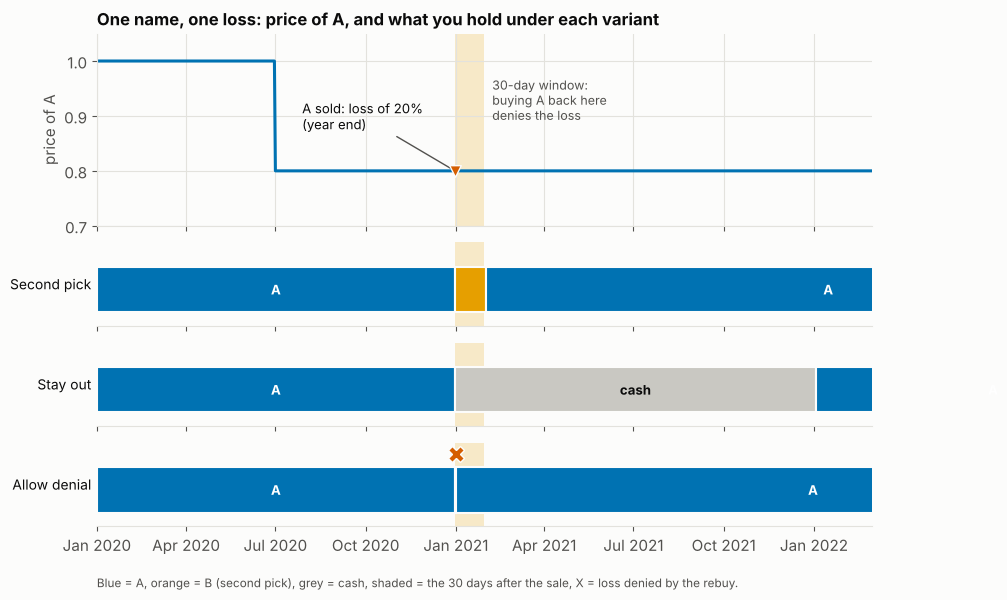

In [4]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 6.4), gridspec_kw=dict(height_ratios=[2.3, 1, 1, 1], hspace=0.15))
sale = pd.Timestamp("2020-12-31"); win = (sale, sale + pd.Timedelta(days=30))
ax = axs[0]
ax.plot(A.index, A.values, color=BLUE, lw=2.2)
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.scatter([sale], [A.loc[sale]], marker="v", s=70, color=RED, zorder=5, edgecolor=SURFACE)
ax.annotate("A sold: loss of 20%\n(year end)", (sale, A.loc[sale]), xytext=(-110, 30), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.text(win[1] + pd.Timedelta(days=8), 0.97, "30-day window:\nbuying A back here\ndenies the loss", fontsize=9, color=INK2, va="top")
ax.set_ylabel("price of A"); ax.set_ylim(0.7, 1.05)
ax.set_title("One name, one loss: price of A, and what you hold under each variant", loc="left", fontsize=12, fontweight="bold")
for ax_, (name, r) in zip(axs[1:], res1.items()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A"), name, window=win, denied_at=h["rebought"] if h["denied"] > 0 else None)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axs[-1].set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-03-01"))
fig.text(0.125, 0.015, "Blue = A, orange = B (second pick), grey = cash, shaded = the 30 days after the sale, X = loss denied by the rebuy.",
         fontsize=8.5, color=INK2)
plt.show()

## 2. With harvesting and without, on a real screen

Now a Globe and Mail screen, **dogs** (the lowest-priced, high-yield names), over 12 years of the synthetic Canadian market, in a **taxable** account in Alberta with $90,000 of other income, rebalanced once a year. Harvesting off, then on: sell any loser down more than 10% at each year end, hold the second pick for 30 days. The synthetic market is made up so the notebook runs offline; the numbers show the machinery, not a forecast.

In [5]:
lab = Lab.synthetic(freq="ME", n_stocks=150, years=12, seed=3)
SCREEN = "dogs"
TAXC = dict(model=CanadianTax("AB", other_income=90_000), capital=100_000, account="taxable")
H_ON = TaxLossHarvest(threshold_pct=0.10, when="year_end", replacement="second_pick")
rep_off = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(**TAXC))
rep_on = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(harvest=H_ON, **TAXC))
off, on = rep_off.results[SCREEN], rep_on.results[SCREEN]
print("harvesting:", H_ON.describe())
cols = ["CAGR", "AfterTaxCAGR", "TaxDrag/yr", "Harvested/yr", "TaxDeferred/yr"]
tab = pd.DataFrame({"harvest off": rep_off.table.loc[SCREEN], "harvest on": rep_on.table.loc[SCREEN]}).reindex(cols)
display(tab.style.format("{:.2%}", na_rep="-"))
d = lambda c: 100 * (rep_on.table.loc[SCREEN, c] - rep_off.table.loc[SCREEN, c])
print(f"change in growth a year, in percentage points: before tax {d('CAGR'):+.2f}, less tax drag {-d('TaxDrag/yr'):+.2f}, after tax {d('AfterTaxCAGR'):+.2f}")
print(f"tax paid over the run: {usd(off.tax['cum_tax_paid'].iloc[-1])} off, {usd(on.tax['cum_tax_paid'].iloc[-1])} on;"
      f" after-tax value of $100,000: {usd(off.after_tax_curve.iloc[-1] * CAP)} off, {usd(on.after_tax_curve.iloc[-1] * CAP)} on")

harvesting: on (threshold 10%, second pick, 30-day window)


,harvest off,harvest on
CAGR,6.69%,6.97%
AfterTaxCAGR,5.83%,6.29%
TaxDrag/yr,0.86%,0.68%
Harvested/yr,-,10.47%
TaxDeferred/yr,-,0.30%


change in growth a year, in percentage points: before tax +0.28, less tax drag +0.17, after tax +0.45
tax paid over the run: $21,419 off, $18,170 on; after-tax value of $100,000: $184,817 off, $193,582 on


**Harvested/yr** is the average loss sold each year as a share of your wealth. **TaxDeferred/yr** is the tax that loss postponed: the library re-runs the same portfolio without harvesting and compares. Note that it is a *deferral*: a harvested loss lowers the cost of what you hold afterwards, so the saving is partly a loan from the taxman (the gain comes back when you sell). **Ignore TaxDeferred/yr in a TFSA or RRSP**; there is nothing to defer.

The before-tax return also changes, because for 30 days you hold a different stock. The line printed under the table splits the after-tax gain into that (luck, in either direction) and the fall in tax drag (the harvest itself).

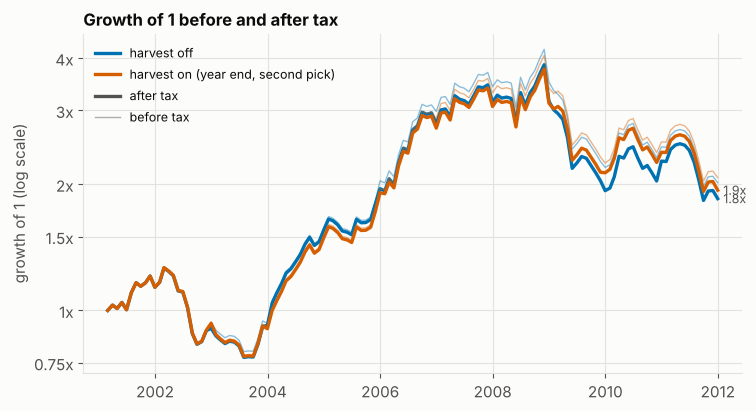

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
after_tax_curves({"harvest off": off, "harvest on (year end, second pick)": on}, ax=ax)
plt.show()

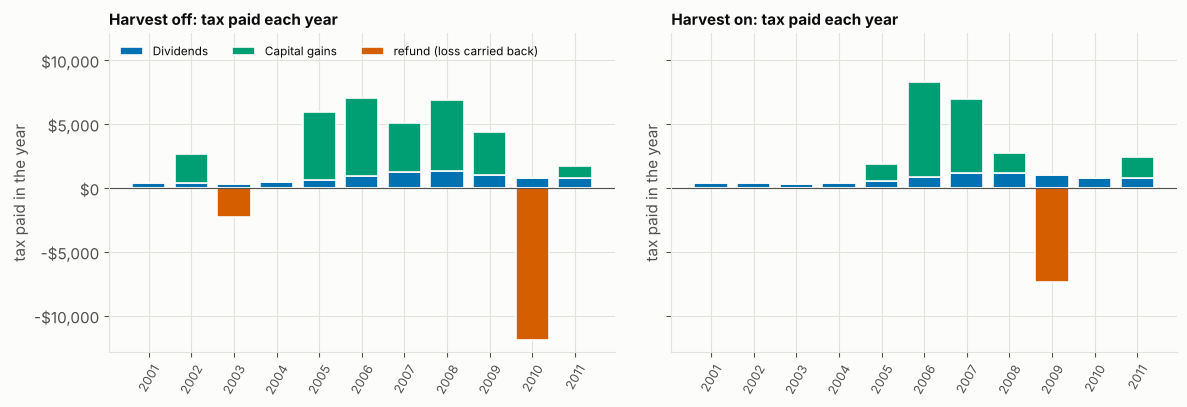

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, res, name in zip(axs, (off, on), ("Harvest off", "Harvest on")):
    tax_paid_stack(res, ax=ax)
    ax.bar(np.arange(len(res.tax)), -res.tax["refund"].to_numpy(), 0.78, color=RED, edgecolor=SURFACE, lw=1.2, label="refund (loss carried back)")
    ax.set_title(f"{name}: tax paid each year", loc="left", fontsize=11, fontweight="bold")
axs[0].legend(loc="upper left", fontsize=8.5, ncol=3)
axs[1].legend().remove()
top = max(ax.get_ylim()[1] for ax in axs)
for ax in axs:
    ax.set_ylim(top=top * 1.3); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
fig.tight_layout(); plt.show()

Red bars below zero are refunds: a net loss carried back to tax already paid in the three previous years (section 3). Booking losses at year end, rather than whenever the screen happens to sell, shifts when the capital gains tax is paid.

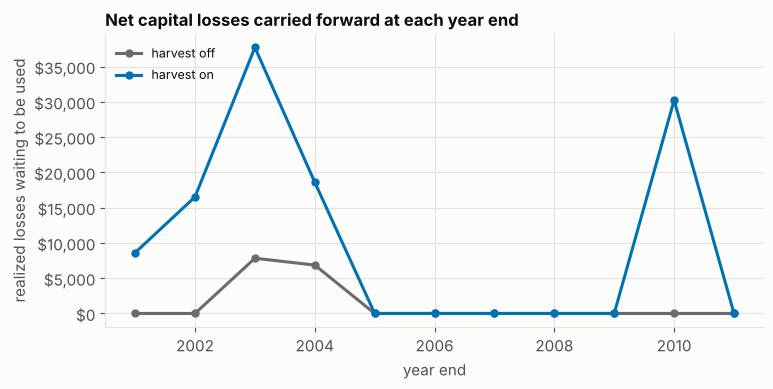

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for res, label, col in ((off, "harvest off", GREY), (on, "harvest on", BLUE)):
    s = res.tax["loss_carry_out"] * 1.0
    ax.plot(s.index, s.values, color=col, lw=2.2, marker="o", ms=5, label=label)
ax.yaxis.set_major_formatter(lambda v, _: usd(v))
ax.set_ylabel("realized losses waiting to be used"); ax.set_xlabel("year end")
ax.set_title("Net capital losses carried forward at each year end", loc="left", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", fontsize=9); plt.show()

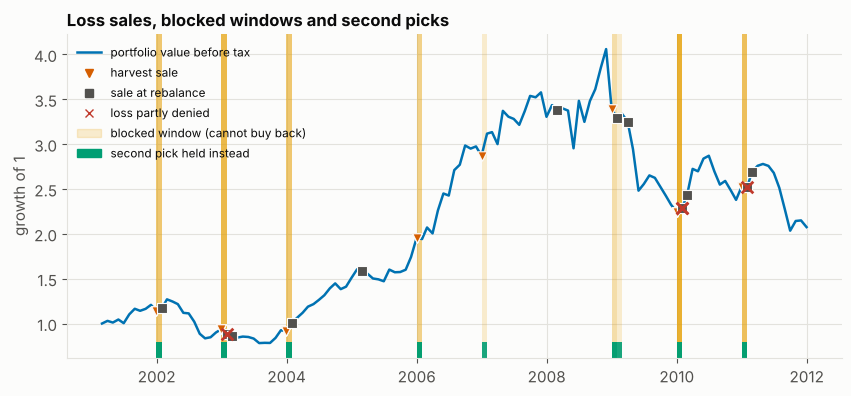

34 harvest sales, 4 with a denied loss, 34 with a second pick held for the window


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
harvest_timeline(on, ax=ax); plt.show()
print(f"{(on.harvest['source'] == 'harvest').sum()} harvest sales, {(on.harvest['denied'] > 0).sum()} with a denied loss,"
      f" {on.harvest['replacement_name'].notna().sum()} with a second pick held for the window")

### How sensitive is it?

Nine runs: a threshold of 5%, 10% or 20% (how far a name must fall before it is sold), and **when**: only at the year end, only at the screen's own rebalance, or both. Each line is after-tax wealth (starting from $100,000) *minus* the same portfolio with harvesting off.

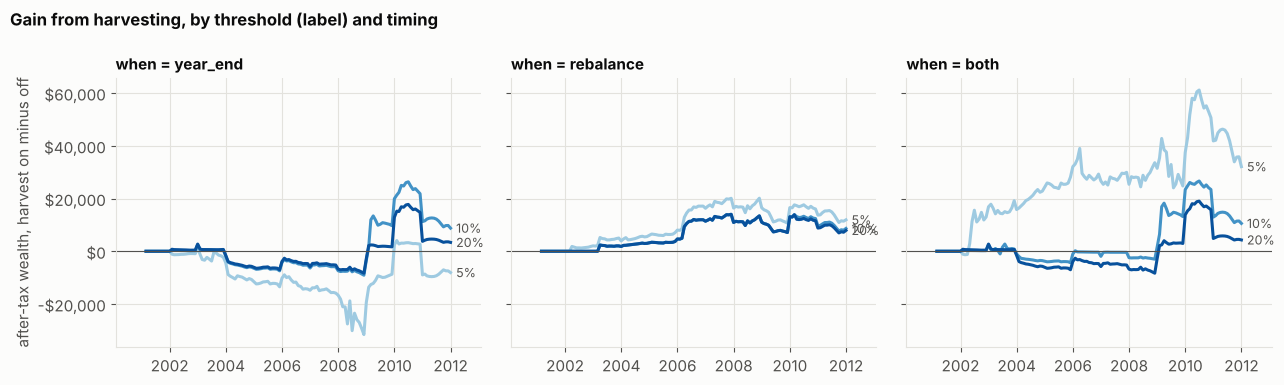

when,year_end,rebalance,both
threshold,,,
0.050000,"-$8,077","$11,921","$32,088"
0.100000,"$8,765","$8,647","$10,561"
0.200000,"$3,361","$7,902","$4,289"


In [10]:
WHEN = ["year_end", "rebalance", "both"]; THR = [0.05, 0.10, 0.20]
curves, srows = {}, []
for when in WHEN:
    for th in THR:
        h = TaxLossHarvest(threshold_pct=th, when=when, replacement="second_pick", report_deferral=False)
        r = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(harvest=h, **TAXC)).results[SCREEN]
        curves[when, th] = (r.after_tax_curve - off.after_tax_curve) * CAP
        srows.append(dict(when=when, threshold=th, gain=(r.after_tax_curve.iloc[-1] - off.after_tax_curve.iloc[-1]) * CAP,
                          harvests=int((r.harvest["source"] == "harvest").sum()) if r.harvest is not None else 0))
sens = pd.DataFrame(srows)
shades = {0.05: "#9ecae1", 0.10: "#4292c6", 0.20: "#08519c"}
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, when in zip(axs, WHEN):
    for th in THR:
        s = curves[when, th]
        ax.plot(s.index, s.values, color=shades[th], lw=2.2)
        ax.annotate(f"{th:.0%}", (s.index[-1], s.values[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2, va="center")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(f"when = {when}", loc="left", fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.margins(x=0.1)
axs[0].set_ylabel("after-tax wealth, harvest on minus off")
fig.suptitle("Gain from harvesting, by threshold (label) and timing", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); plt.show()
display(sens.pivot(index="threshold", columns="when", values="gain")[WHEN].style.format(usd).set_caption("After-tax gain at the end ($)"))

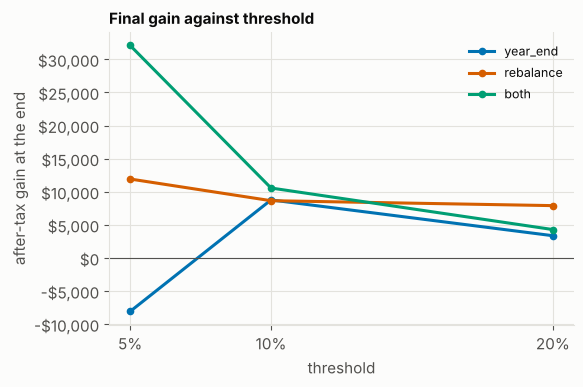

In [11]:
wide = sens.pivot(index="threshold", columns="when", values="gain")[WHEN].reset_index()
fig, ax = plt.subplots(figsize=(6, 3.8))
sensitivity_lines(wide, "threshold", {w: w for w in WHEN}, ax=ax)
ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_xticks(THR, [f"{t:.0%}" for t in THR])
ax.set_ylabel("after-tax gain at the end"); ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Final gain against threshold", loc="left", fontsize=11, fontweight="bold"); plt.show()

A lower threshold harvests more often but sells names that may recover, and each swap into a second pick and back can realize small gains. The gains here come from one synthetic history; read the *direction* and the *order of magnitude*, not the dollars.

## 3. Carry-back: a loss that refunds tax already paid

Canada lets you apply a net capital loss to the taxable gains of the **three previous years** (most recent first) and get that tax back. Whatever is left carries forward. Two cases with a flat 20% rate: gains taxed in three years, then a loss in the fourth; and a loss big enough to run out of years.

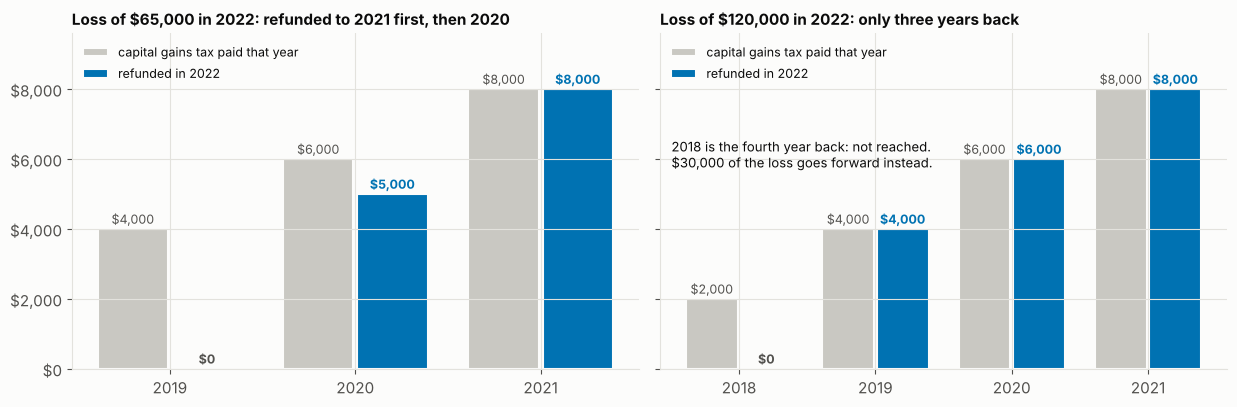

,"case 1 ($65,000 loss)","case 2 ($120,000 loss)"
realized_losses,"-$65,000","-$120,000"
carried_back,"$65,000","$90,000"
refund,"$13,000","$18,000"
loss_carry_out,$0,"$30,000"


carry-back refund: case 1 $13,000, case 2 $18,000; carried forward in case 2: $30,000


In [12]:
def carry_events(years):
    idx = pd.date_range("2018-01-01", "2023-12-31", freq="D")
    ev = pd.DataFrame(0.0, index=idx, columns=["div_ca", "div_fx", "gain", "loss"])
    for y, (g, l) in years.items():
        ev.loc[f"{y}-06-01", ["gain", "loss"]] = [g, l]
    return pd.Series(1.0, index=idx), ev

def carry_case(years):
    curve, ev = carry_events(years)
    t, _ = assess(curve, ev, TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False), CAP)
    return t

# gains are in units of the $100,000 start: 0.20 = $20,000
case1 = carry_case({2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -0.65)})
case2 = carry_case({2018: (0.10, 0), 2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -1.20)})

def carry_chart(t, ax, title, years, loss_year=2022):
    by = t.attrs["year_tax"][loss_year].breakdown["refund_by_year"]
    x = np.arange(len(years)); paid = [t.loc[y, "tax_capital_gains"] for y in years]; back = [by.get(y, 0.0) for y in years]
    ax.bar(x - 0.2, paid, 0.38, color="#c9c8c2", label="capital gains tax paid that year", edgecolor=SURFACE, lw=1.5)
    ax.bar(x + 0.2, back, 0.38, color=BLUE, label=f"refunded in {loss_year}", edgecolor=SURFACE, lw=1.5)
    for xi, p, b in zip(x, paid, back):
        ax.text(xi - 0.2, p + 150, usd(p), ha="center", fontsize=9, color=INK2)
        ax.text(xi + 0.2, b + 150, usd(b), ha="center", fontsize=9, color=BLUE if b else INK2, fontweight="bold")
    ax.set_xticks(x, [str(y) for y in years]); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
    ax.set_ylim(0, max(paid) * 1.2)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold"); ax.legend(loc="upper left", fontsize=9)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
carry_chart(case1, axs[0], "Loss of $65,000 in 2022: refunded to 2021 first, then 2020", [2019, 2020, 2021])
carry_chart(case2, axs[1], "Loss of $120,000 in 2022: only three years back", [2018, 2019, 2020, 2021])
axs[1].text(0.02, 0.60, "2018 is the fourth year back: not reached.\n$30,000 of the loss goes forward instead.", transform=axs[1].transAxes,
            ha="left", fontsize=9.5, color=INK)
fig.tight_layout(); plt.show()
show = pd.DataFrame({"case 1 ($65,000 loss)": case1.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]],
                     "case 2 ($120,000 loss)": case2.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]]})
display(show.style.format(usd))
print(f"carry-back refund: case 1 {usd(case1.loc[2022, 'refund'])}, case 2 {usd(case2.loc[2022, 'refund'])};"
      f" carried forward in case 2: {usd(case2.loc[2022, 'loss_carry_out'])}")

The loss year's `tax_paid` becomes a **credit** (negative), which is the refund you would get when you file for the loss year. In a real return you ask for it with form T1A; the model assumes you do. A forward balance is not carried back later: it only offsets future gains.

## 4. Exits: the sale that a risk signal makes

An exit policy parks the portfolio in cash while a risk flag is on, which sells everything, including a name sitting on a loss. That sale is a loss like any other, so the stage records it (`source` "exit") and blocks the name. Here the flag goes on at **S = 1 September 2020**, when A is down 20% (it was bought at 1.0). A is back to 1.0 on 20 September and to 1.1 on 5 October. Three ways the flag can clear:

* **S + 10 days, second pick.** A is blocked until S + 30, so B takes the money, and A comes back at S + 31.
* **S + 31 days.** The window has just passed: A is bought straight back.
* **S + 10 days, allow denial.** A is bought back at once; the loss is denied.

In [13]:
class Flag:
    "A risk flag set by hand: on for the calendar days from `start` to `end`."
    name = "flag"
    def __init__(self, start, end):
        self.start, self.end = pd.Timestamp(start), pd.Timestamp(end)
    def compute(self, mkt, macro=None):
        return pd.Series(((mkt.index >= self.start) & (mkt.index <= self.end)).astype(float), index=mkt.index)

S = pd.Timestamp("2020-09-01")
a_exit = step(("2020-07-01", 0.8), ("2020-09-20", 1.0), ("2020-10-05", 1.1))
mk4 = toy_market(dict(A=a_exit, B=FLAT, C=FLAT), caps)

def exit_run(back_on, harvest):
    pol = ExitPolicy(ExitScreen([Flag(S, back_on - pd.Timedelta(days=1))], threshold=0.5, lag=0), switch_cost_bps=0.0)
    return toy_run(mk4, 1, harvest, exit=pol)

EXITS = {"back S+10, second pick": (S + pd.Timedelta(days=10), TaxLossHarvest(replacement="second_pick")),
         "back S+31, second pick": (S + pd.Timedelta(days=31), TaxLossHarvest(replacement="second_pick")),
         "back S+10, allow denial": (S + pd.Timedelta(days=10), TaxLossHarvest(on_repick="allow_denial"))}
res4 = {k: exit_run(b, h) for k, (b, h) in EXITS.items()}
rows = []
for k, r in res4.items():
    h = r.harvest.iloc[0]
    rows.append({"variant": k, "sale recorded as": h["source"], "name": h["name"], "loss": usd(h["loss"] * CAP),
                 "bought instead": h["replacement_name"] if isinstance(h["replacement_name"], str) else "A (the same name)",
                 "A held again on": h["rebought"].date(), "denied": usd(h["denied"] * CAP),
                 "wealth on 6 Oct": usd(r.curve.loc["2020-10-06"] * CAP), "loss realized in 2020": usd(abs(r.tax.loc[2020, "realized_losses"]))})
display(pd.DataFrame(rows).set_index("variant"))

,sale recorded as,name,loss,bought instead,A held again on,denied,wealth on 6 Oct,loss realized in 2020
variant,,,,,,,,
"back S+10, second pick",exit,A,"$20,000",B,2020-10-02,$0,"$88,000","$20,000"
"back S+31, second pick",exit,A,"$20,000",A (the same name),2020-10-02,$0,"$88,000","$20,000"
"back S+10, allow denial",exit,A,"$20,000",A (the same name),2020-09-11,"$20,000","$110,000",$0


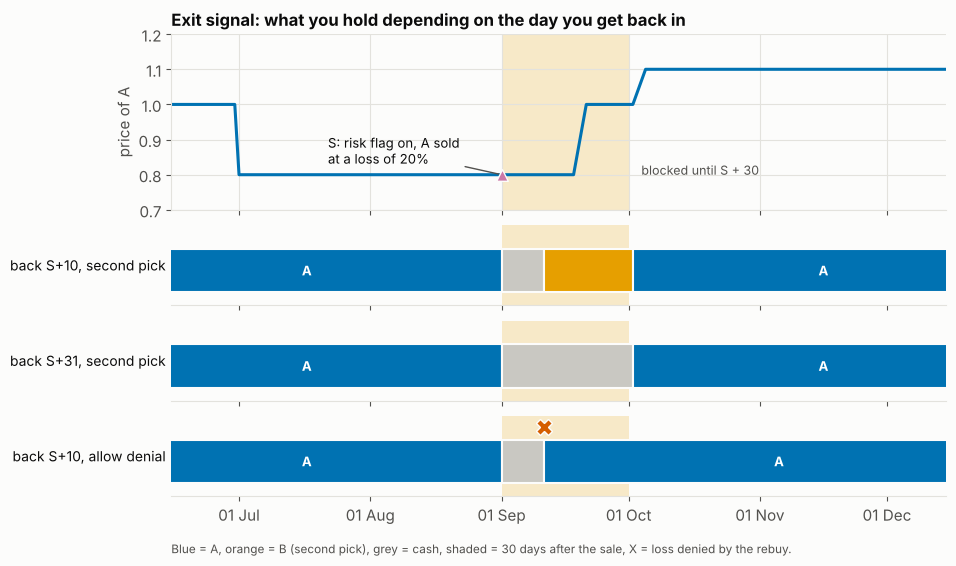

In [14]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 6), gridspec_kw=dict(height_ratios=[2.2, 1, 1, 1], hspace=0.15))
win = (S, S + pd.Timedelta(days=30)); ax = axs[0]
ax.plot(a_exit.index, a_exit.values, color=BLUE, lw=2.2)
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.scatter([S], [a_exit.loc[S]], marker="^", s=70, color="#CC79A7", zorder=5, edgecolor=SURFACE)
ax.annotate("S: risk flag on, A sold\nat a loss of 20%", (S, a_exit.loc[S]), xytext=(-125, 8), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.text(S + pd.Timedelta(days=33), 0.80, "blocked until S + 30", fontsize=9, color=INK2)
ax.set_ylabel("price of A"); ax.set_ylim(0.7, 1.2)
ax.set_title("Exit signal: what you hold depending on the day you get back in", loc="left", fontsize=12, fontweight="bold")
for ax_, (name, (b, _)), r in zip(axs[1:], EXITS.items(), res4.values()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A", end=pd.Timestamp("2020-12-31"), reentry=b, start=pd.Timestamp("2020-06-01")), name, window=win,
              denied_at=b if h["denied"] > 0 else None)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axs[-1].set_xlim(pd.Timestamp("2020-06-15"), pd.Timestamp("2020-12-15"))
fig.text(0.125, 0.015, "Blue = A, orange = B (second pick), grey = cash, shaded = 30 days after the sale, X = loss denied by the rebuy.",
         fontsize=8.5, color=INK2)
plt.show()

## 5. Reading guide

**What this tells you.** How much of the tax benefit of selling losers survives the superficial-loss rule when the portfolio is kept invested by a second pick; how big the effect is on a rule-based screen (in the synthetic market the tax drag fell by under 0.2 points a year; the rest of the after-tax gain came from the second picks happening to do better than the names they replaced, which is luck and can go either way; the sensitivity table swings from a loss to a gain between settings for the same reason); what carry-back adds when a loss follows gain years; that an exit-policy sale is a loss sale like any other, and how its re-entry is steered.

**What it ignores.**

* **Spouse and affiliated accounts.** CRA also denies the loss if your spouse, your RRSP or TFSA, or a corporation you control buys the same name in the window. The model sees one taxable account only.
* **Identical property.** Swapping one ETF for another that tracks the same index may or may not be "identical" for CRA; the model only knows names, and a second pick is a different company.
* **Settlement dates.** Trades are on trade dates; the real rule uses settlement dates (two business days later in the market of the day).
* **"Still held at the end of the window".** The rule bites only if you still hold the rebought shares at the end of the 30 days. The model treats any repurchase in the window as denying the loss, which is the cautious reading and slightly overstates the denial.
* **Small details.** Transaction costs on the swaps, bid-ask spread, and the real price of 30 days away from the name (the second pick may go up or down more than the original would have).
* **TFSA and RRSP.** A loss inside a registered account is worthless, so harvesting there is pointless. In a registered account **ignore the TaxDeferred/yr column**: it is computed anyway but nothing is deferred.
* **Tax law.** The flat 20% in sections 1, 3 and 4 is for clean arithmetic; section 2 uses the library's Alberta model with brackets. Neither is tax advice.

**Where to look next.** `docs/TAXES.md`, "Loss harvesting"; `tests/test_harvesting.py` (the markets above, with every number asserted); `notebooks/accounts_and_foreign.ipynb` for which account a portfolio should live in.